<h1><center> Deep Learning pour les séries temporelles

### 1. Génération des données

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)

time = np.arange(0, 500)
series = np.sin(time * 0.1) * 10 + (time * 0.05) + np.random.normal(0, 1, 500)

dates = pd.date_range(start="2024-01-01", periods=500, freq="D")
df = pd.DataFrame({"Valeur": series}, index=dates)

df.head()

,Valeur
2024-01-01,0.496714
2024-01-02,0.910070
2024-01-03,2.734382
2024-01-04,4.628232
2024-01-05,3.860030


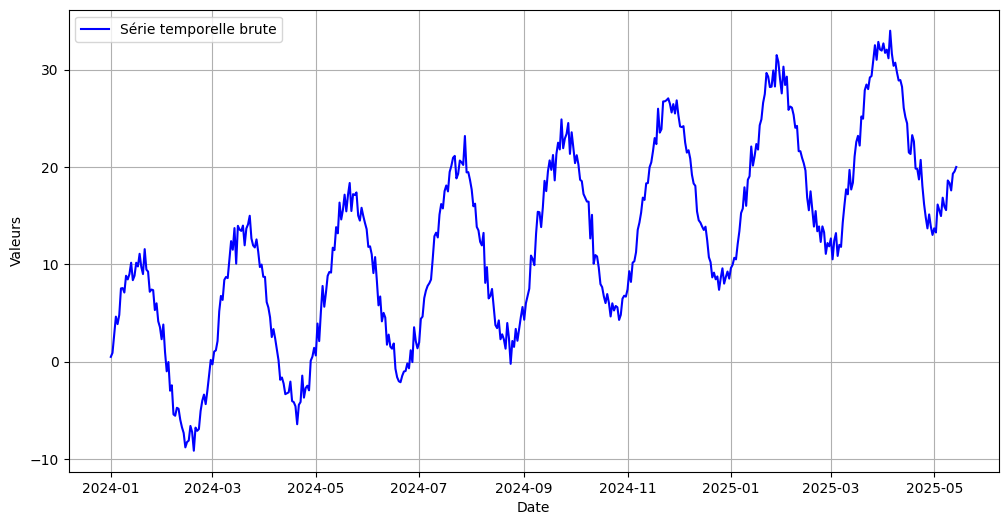

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(df.index, df["Valeur"], label= "Série temporelle brute", color="blue")
plt.xlabel("Date")
plt.ylabel("Valeurs")
plt.legend()
plt.grid(True)
plt.show()

### 2. Normalisation des données

In [3]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))

df["scaled_data"] = scaler.fit_transform(df[["Valeur"]])

df.head()

,Valeur,scaled_data
2024-01-01,0.496714,0.223429
2024-01-02,0.910070,0.233015
2024-01-03,2.734382,0.275322
2024-01-04,4.628232,0.319243
2024-01-05,3.860030,0.301427


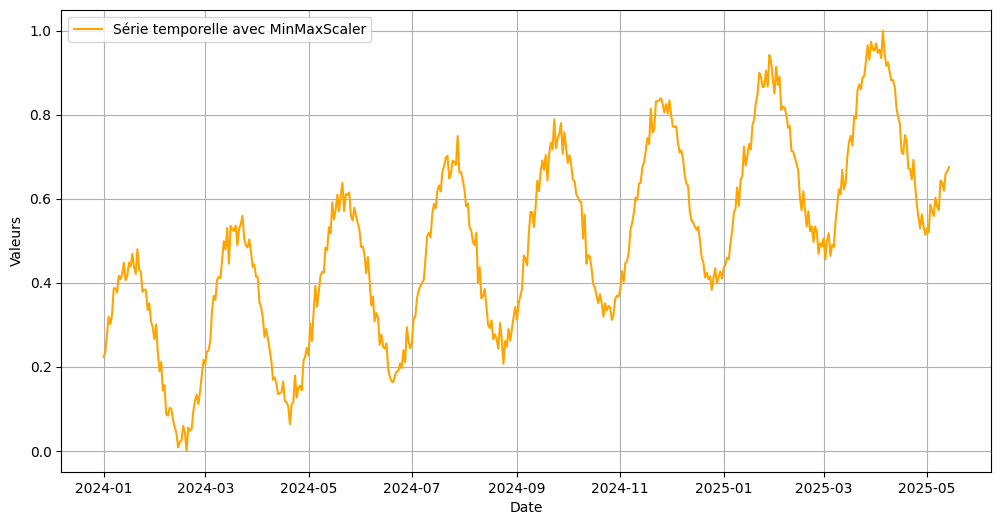

In [5]:
plt.figure(figsize=(12,6))
plt.plot(df.index, df["scaled_data"], label= "Série temporelle avec MinMaxScaler", color="orange")
plt.xlabel("Date")
plt.ylabel("Valeurs")
plt.legend()
plt.grid(True)
plt.show()

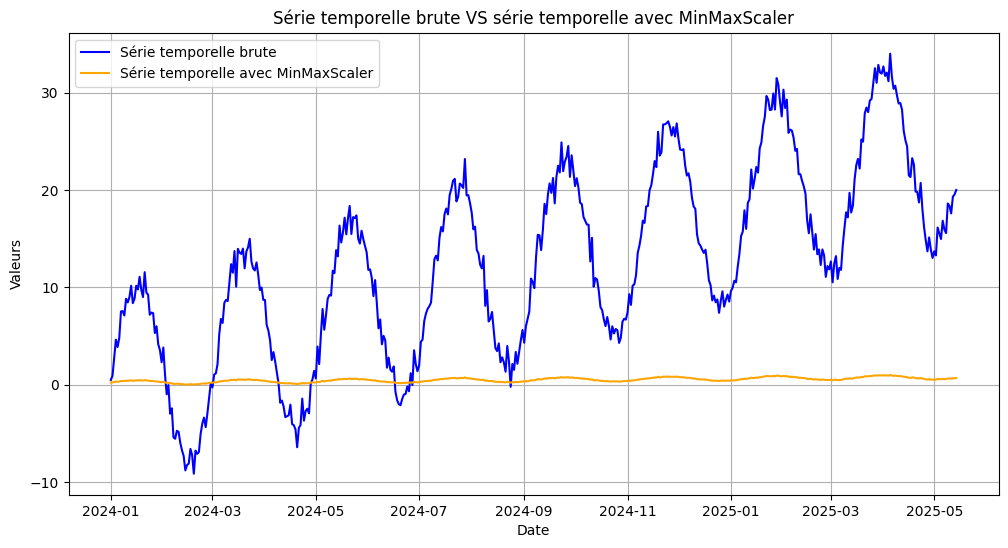

In [6]:
plt.figure(figsize=(12,6))
plt.plot(df.index, df["Valeur"], label= "Série temporelle brute", color="blue")
plt.plot(df.index, df["scaled_data"], label= "Série temporelle avec MinMaxScaler", color="orange")
plt.title("Série temporelle brute VS série temporelle avec MinMaxScaler")
plt.xlabel("Date")
plt.ylabel("Valeurs")
plt.legend()
plt.grid(True)
plt.show()

### 3. Création des séquences

La fonction suivante transforme la série en paires de séquences (X, y) où chaque X contient une fenêtre de lookback = 20 pas de temps, et y est la valeur suivante à prédire.

<b>Pourquoi créer des séquences ?</b>

Un réseau de neurones récurrent (comme le LSTM) a besoin d'un contexte pour savoir où va le temps. 

Si on donne juste le point d'aujourd'hui, LSTM ne peut pas deviner si la série monte ou descend. 

En créant une fenêtre de lookback = 20, on donne les 20 derniers jours pour qu'il peut savoir la dynamique (la vitesse, l'inertie, la direction).

In [9]:
scaled_data = scaler.fit_transform(df[["Valeur"]])

In [7]:
def create_sequence(data, lookback):
    X, y = [], []
    for i in range(len(data)- lookback):
        X.append(data[i: (i+lookback), 0])
        y.append(data[i+ lookback, 0])
    return np.array(X), np.array(y)



In [10]:
lookback = 20
X, y = create_sequence(scaled_data, lookback)



In [12]:
X[0]

array([0.2234286 , 0.23301474, 0.27532236, 0.31924263, 0.30142726,
       0.32346076, 0.38643637, 0.38722426, 0.37666018, 0.41658911,
       0.40790323, 0.42054352, 0.44758444, 0.40607136, 0.41667609,
       0.44759161, 0.43878466, 0.46888636, 0.43756823, 0.42064448])

In [13]:
y[0]

0.47996533806033004

### 4. Modèle LSTM

In [14]:
import torch
import torch.nn as nn


In [ ]:
# Reshape pour PyTorch [samples, time steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

# Découpage des données en Train / Test 
train_size = int(len(X) * 0.8)
X_train, X_test = X_tensor[:train_size], X_tensor[train_size:]
y_train, y_test = y_tensor[:train_size], y_tensor[train_size:]


# OU BIEN TOUS SIMPLEMENT
#from sklearn.model_selection import train_test_split
#X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size= 0.2, shuffle= False)

In [16]:
print(len(X_train), len(y_train), len(X_test), len(y_test))

384 384 96 96


In [20]:
X_train.shape, y_train.shape

(torch.Size([384, 20, 1]), torch.Size([384, 1]))

In [19]:
X_test.shape, y_test.shape

(torch.Size([96, 20, 1]), torch.Size([96, 1]))

In [21]:
class SimpleLSTM(nn.Module):
    def __init__(self, input_dim= 1, hidden_dim= 32, output_dim= 1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first= True)
        self.fc = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

In [22]:
model = SimpleLSTM()


In [23]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr= 0.01)

In [24]:
epochs = 50
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 10 == 0:
        print(f"Époque [{epoch+1}/{epochs}], Perte (Loss): {loss.item():.5f}")

Époque [10/50], Perte (Loss): 0.03358
Époque [20/50], Perte (Loss): 0.02351
Époque [30/50], Perte (Loss): 0.00926
Époque [40/50], Perte (Loss): 0.00349
Époque [50/50], Perte (Loss): 0.00171


In [25]:
model.eval()
with torch.no_grad():
    train_predict = model(X_train)
    test_predict = model(X_test)

In [26]:
# Inversion de la normalisation pour comparer dans l'échelle d'origine
train_predict_inv = scaler.inverse_transform(train_predict.numpy())
test_predict_inv = scaler.inverse_transform(test_predict.numpy())
y_test_inv = scaler.inverse_transform(y_test.numpy())

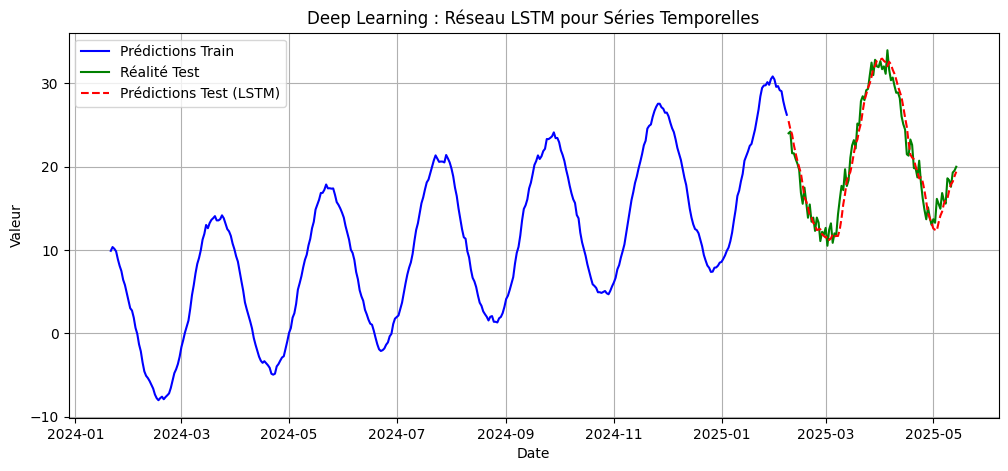

In [27]:
plt.figure(figsize=(12, 5))
plt.plot(df.index[lookback:lookback+train_size], train_predict_inv, label="Prédictions Train", color="blue")
plt.plot(df.index[lookback+train_size:], y_test_inv, label="Réalité Test", color="green")
plt.plot(df.index[lookback+train_size:], test_predict_inv, label="Prédictions Test (LSTM)", color="red", linestyle="--")
plt.title("Deep Learning : Réseau LSTM pour Séries Temporelles")
plt.xlabel("Date")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True)
plt.show()